# ДЗ1 · Исследовательский анализ данных

## Кратко

Разбираем данные задачи **PNG чертежа → новая M3D с деревом построения**:
происхождение, размеры изображений, комплектность, соответствие пар и риски утечек.
Таблицы и графики пересчитываются из файлов репозитория; сохранённые результаты можно
просмотреть прямо на GitHub.

**Границы анализа:** по исходному корпусу из 27 пар опубликованы агрегаты происхождения
и типов файлов. Подробные измерения ниже относятся только к учебному набору
KF0011 / KF0017 / KF0027. По остальным деталям мы не оцениваем разрешение изображений,
дубликаты, полноту размеров или качество эталонов.

Ноутбук добавлен **после завершения baseline**. Это описательный анализ фиксированной
поставки, а не свидетельство того, что все эти графики использовались при первоначальном
отборе. Он не меняет промпты, split, пороги или результаты сданного опыта.


## 1. Источники и проверка целостности

- [manifest.json](../data/hw01/v1/manifest.json): состав набора, происхождение, split,
  семейства, агрегаты исходного корпуса.
- [SHA256.json](../data/hw01/v1/SHA256.json): контрольные суммы опубликованных данных.
- `inputs/<ID>/drawing.png`: единственный вход генератора.
- `qa/<ID>/review.json` и `eval-facts.json`: сохранённая ручная проверка номинальных
  размеров и нативные измерения эталонов; **генератору они недоступны**.

Все ячейки работают офлайн и не открывают КОМПАС. Полная M3D нужна здесь для проверки
хеша, а не для извлечения геометрии. Исходные файлы не изменяются.


In [1]:
import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents) if (path / "data/hw01/v1/manifest.json").is_file()
)
DATA = ROOT / "data/hw01/v1"


def read_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding="utf-8"))


manifest = read_json(DATA / "manifest.json")
inventory = read_json(DATA / "SHA256.json")
for relative, expected in inventory.items():
    path = (DATA / relative).resolve()
    assert path.is_relative_to(DATA.resolve()), relative
    assert hashlib.sha256(path.read_bytes()).hexdigest() == expected, relative

plt.rcParams.update(
    {"font.size": 11, "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)
pd.set_option("display.max_colwidth", 65)
pd.set_option("display.max_columns", 14)
print(f"Набор: {manifest['dataset_id']} / {manifest['version']}")
print(f"SHA256 подтверждён для всех {len(inventory)} файлов описи.")
print(f"Python {sys.version.split()[0]}; pandas {pd.__version__}; numpy {np.__version__}")

Matplotlib is building the font cache; this may take a moment.


Набор: hw01-cad-pilot / v1
SHA256 подтверждён для всех 26 файлов описи.
Python 3.14.5; pandas 3.1.1; numpy 2.5.4


## 2. Состав исходного корпуса

Единица наблюдения — пара «лист одной детали ↔ эталонная модель». Это генеративная
задача, классов и целевой метки классификации нет. Вместо дисбаланса классов смотрим
на представленность источников. Папка источника **не равна семейству геометрически
родственных деталей**.

Агрегаты ниже сохранены в манифесте учебного набора и связаны с исходным манифестом
его SHA256. Исходный манифест целиком не входит в поставку, поэтому его агрегаты
здесь показываются, но не пересчитываются по 27 исходным файлам.


In [2]:
counts = manifest["corpus_counts"]
display(pd.DataFrame([counts]).rename(columns={"pairs": "пары"}))
source_groups = pd.Series(manifest["corpus_source_groups"], name="Пар в корпусе")
assert source_groups.sum() == counts["pairs"]
selected_sources = pd.Series([item["source_group"] for item in manifest["items"]]).value_counts()
composition = source_groups.to_frame()
composition["Доля корпуса, %"] = 100 * composition["Пар в корпусе"] / counts["pairs"]
composition["В учебном наборе"] = selected_sources.reindex(composition.index, fill_value=0)
composition.index.name = "Папка происхождения"
display(composition.round(1))
print("SHA256 исходного манифеста:", manifest["source_manifest_sha256"])

,пары,png,pdf,m3d,cdw
0,27,27,0,27,27


,Пар в корпусе,"Доля корпуса, %",В учебном наборе
Папка происхождения,,,
Samples/Reducer,10,37.0,2
Samples/Shaft/2D/Валы,4,14.8,0
Samples/Shaft/2D/Вырезы по круговому массиву,7,25.9,1
Samples/Shaft/2D/Пазы шпоночные,6,22.2,0


SHA256 исходного манифеста: d30c18b4eaa2f93180e05eed0a8e63be0d02936abb31be982ec1ed5f05d3da99


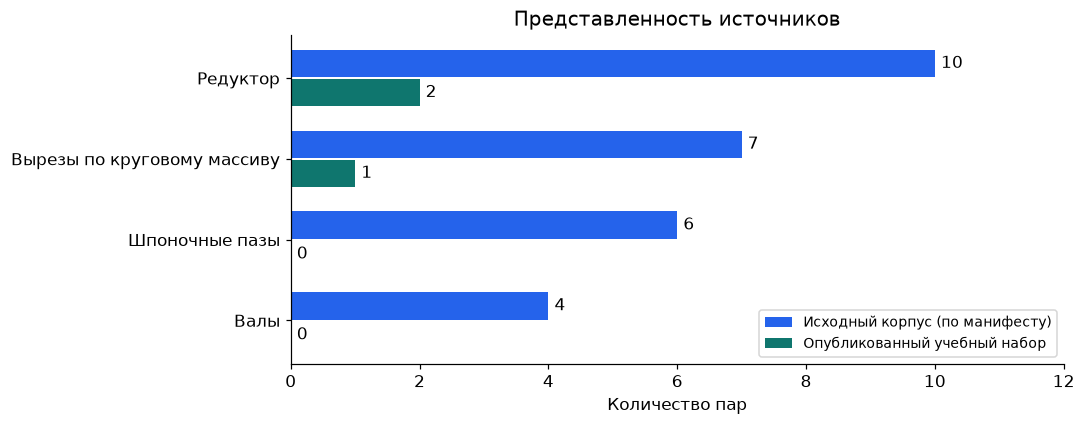

In [3]:
labels = {
    "Samples/Reducer": "Редуктор",
    "Samples/Shaft/2D/Валы": "Валы",
    "Samples/Shaft/2D/Вырезы по круговому массиву": "Вырезы по круговому массиву",
    "Samples/Shaft/2D/Пазы шпоночные": "Шпоночные пазы",
}
plot_data = composition.sort_values("Пар в корпусе")
y = np.arange(len(plot_data))
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(
    y + 0.18, plot_data["Пар в корпусе"], height=0.34, label="Исходный корпус (по манифесту)", color="#2563eb"
)
ax.bar_label(bars, padding=4)
bars = ax.barh(
    y - 0.18,
    plot_data["В учебном наборе"],
    height=0.34,
    label="Опубликованный учебный набор",
    color="#0f766e",
)
ax.bar_label(bars, padding=4)
ax.set(
    yticks=y,
    yticklabels=[labels[name] for name in plot_data.index],
    xlabel="Количество пар",
    xlim=(0, 12),
    title="Представленность источников",
)
ax.set_xticks(range(0, 13, 2))
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
plt.show()

**Интерпретация.** Набор для ДЗ целенаправленный: в нём нет валов и примеров
шпоночных пазов. Нельзя переносить результат на эти группы или на весь корпус.
Разное число объектов по папкам не даёт оснований для балансировки классов:
классов в этой задаче нет. Все изображения — экспорты чертежей, не сканы и не фотографии.


## 3. Учебный набор: файлы, признаки и пропуски

На inference доступны только пиксели PNG и общие инструменты. Идентификатор пары,
папка источника, M3D, CDW, QA и split — **метаданные исследования**, не дополнительные
признаки для генератора. Разрешение и размер файла описывают вход; они не являются
оценкой сложности CAD или полноты размерных обозначений.


In [4]:
records = []
for item in manifest["items"]:
    image_record = item["input_png"]
    path = DATA / image_record["path"]
    with Image.open(path) as picture:
        width, height = picture.size
        mode = picture.mode
        histogram = np.asarray(picture.convert("L").histogram(), dtype=np.int64)
    assert (width, height) == (image_record["width_px"], image_record["height_px"])
    assert path.stat().st_size == image_record["bytes"]
    records.append(
        {
            "pair_id": item["pair_id"],
            "split": item["split"],
            "family": item["family"],
            "source_group": item["source_group"],
            "width_px": width,
            "height_px": height,
            "megapixels": width * height / 1_000_000,
            "png_KiB": path.stat().st_size / 1024,
            "mode": mode,
            "dark_pixels_pct": 100 * histogram[:245].sum() / histogram.sum(),
            "pair_validation": item["pair_validation"],
        }
    )
selected = pd.DataFrame(records).set_index("pair_id")
display(selected[["split", "family", "source_group", "pair_validation"]])
display(selected[["width_px", "height_px", "megapixels", "png_KiB", "mode"]].round(3))
availability = pd.DataFrame(
    {
        item["pair_id"]: {
            field: bool(item.get(field)) and (DATA / item[field]["path"]).is_file()
            for field in ("input_png", "source_cdw", "reference_m3d", "input_pdf")
        }
        for item in manifest["items"]
    }
).T
availability.index.name = "pair_id"
display(
    availability.rename(
        columns={"input_png": "PNG", "source_cdw": "CDW", "reference_m3d": "M3D", "input_pdf": "PDF"}
    )
)

,split,family,source_group,pair_validation
pair_id,,,,
KF0011,dev,reducer_gear_0102,Samples/Reducer,known_mismatch_dev_only
KF0017,val,slotted_bushing_0108,Samples/Reducer,passed
KF0027,val,mounting_ring_2k52,Samples/Shaft/2D/Вырезы по круговому массиву,passed


,width_px,height_px,megapixels,png_KiB,mode
pair_id,,,,,
KF0011,4962,3509,17.412,372.293,RGB
KF0017,2481,3509,8.706,178.434,RGB
KF0027,4962,3509,17.412,269.325,RGB


,PNG,CDW,M3D,PDF
pair_id,,,,
KF0011,True,True,True,False
KF0017,True,True,True,False
KF0027,True,True,True,False


**Отсутствие файла и отсутствие размера — разные виды пропусков.** В выбранных парах
есть обязательные PNG/CDW/M3D. PDF не предусмотрен этой версией набора и не является
потерянным обязательным входом. Размер может отсутствовать даже на читаемом, исправном PNG.

По 27 листам нет опубликованной разметки полноты размеров: количественную долю таких
пропусков здесь не оцениваем. По `val` используем только сохранённые проверки выбранных
пар, приведённые ниже. Автоматически извлечённые размеры и OCR в этом EDA не используются.


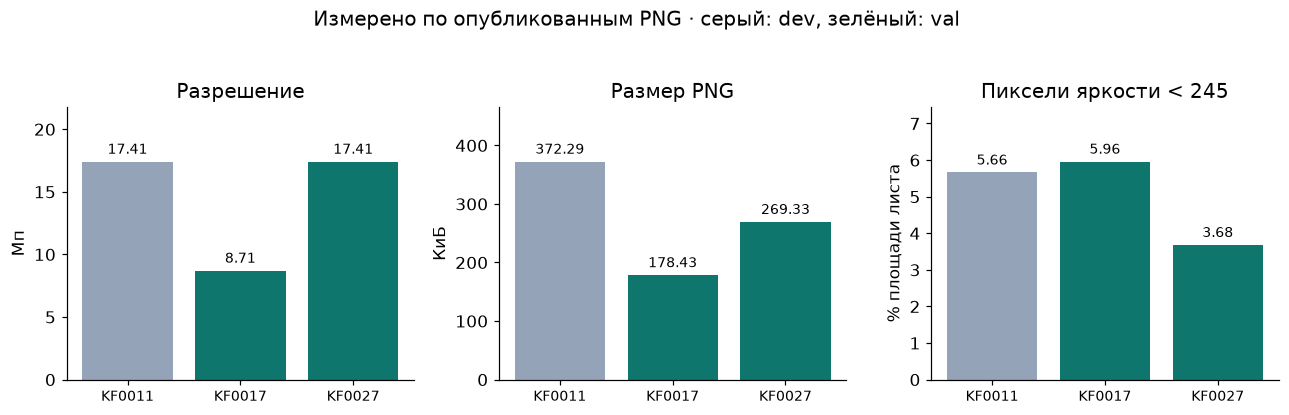

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for axis, column, title, unit in zip(
    axes,
    ["megapixels", "png_KiB", "dark_pixels_pct"],
    ["Разрешение", "Размер PNG", "Пиксели яркости < 245"],
    ["Мп", "КиБ", "% площади листа"],
    strict=True,
):
    values = selected[column]
    bars = axis.bar(selected.index, values, color=["#94a3b8", "#0f766e", "#0f766e"])
    axis.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
    axis.set(title=title, ylabel=unit, ylim=(0, values.max() * 1.25))
    axis.tick_params(axis="x", labelsize=9)
fig.suptitle("Измерено по опубликованным PNG · серый: dev, зелёный: val", y=1.04)
fig.tight_layout()
plt.show()

Доля тёмных пикселей — простая характеристика заполненности листа. Порог 245 из 255
применён только для описательного графика и **не входит в baseline или оценщик**.
Он не отделяет линии детали от текста, рамки и штриховки. По этому показателю нельзя
судить о количестве операций, читаемости размеров или корректности пары.

Детали имеют разные форматы листа. Поэтому одинаковое уменьшение PNG даёт разный размер
мелкого текста на экране. В baseline разрешён просмотр фрагментов оригинального листа,
но этот EDA не измеряет причинный эффект увеличения фрагментов.


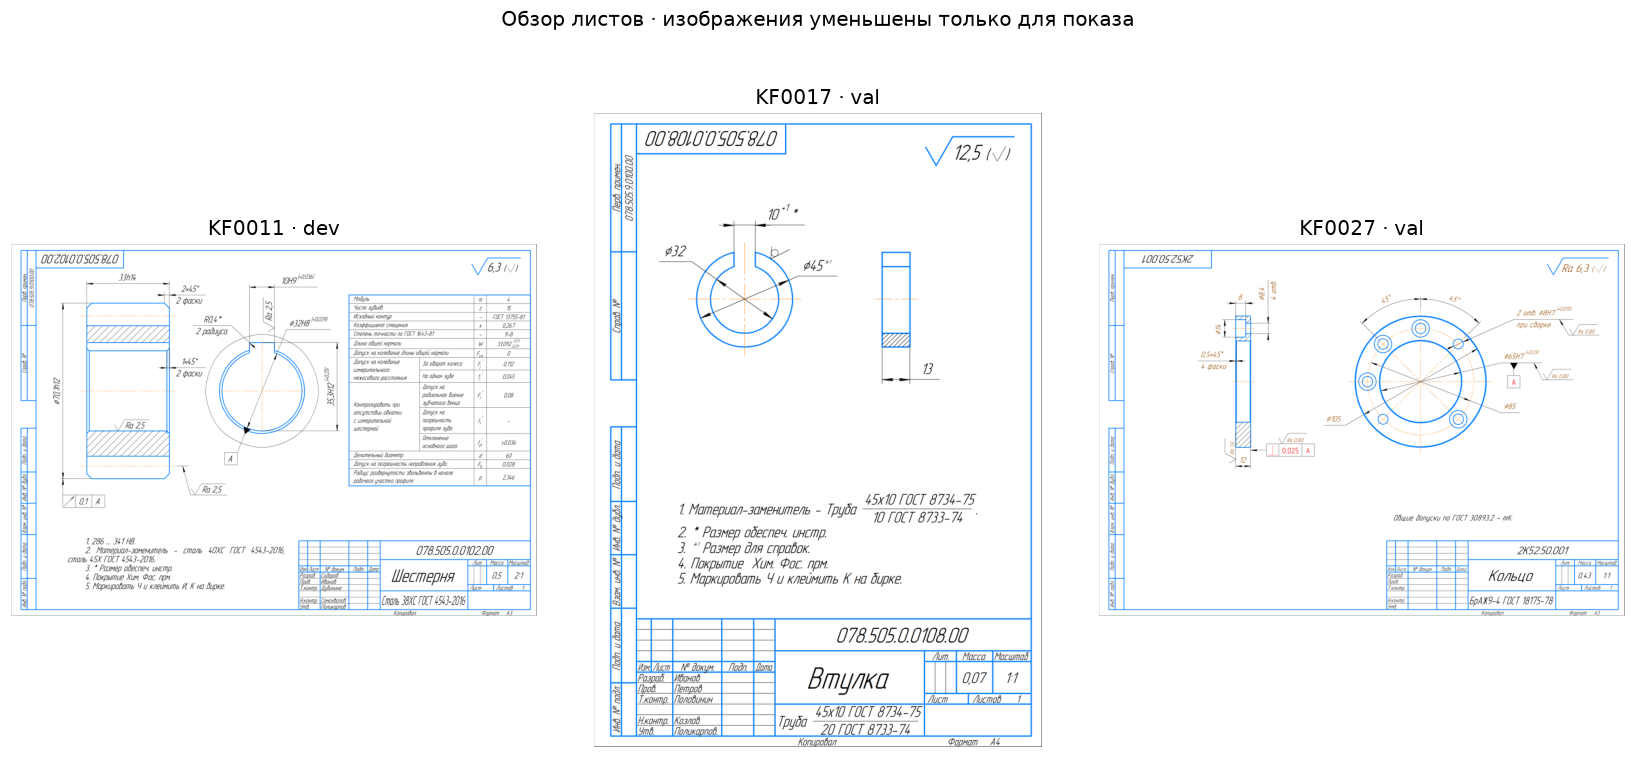

In [6]:
fig, axes = plt.subplots(1, len(manifest["items"]), figsize=(15, 7))
for axis, item in zip(axes, manifest["items"], strict=True):
    with Image.open(DATA / item["input_png"]["path"]) as original:
        preview = original.convert("RGB")
        preview.thumbnail((1100, 1100))
    axis.imshow(preview)
    axis.set_title(f"{item['pair_id']} · {item['split']}")
    axis.set_axis_off()
fig.suptitle("Обзор листов · изображения уменьшены только для показа")
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

[Оригинал KF0011](../data/hw01/v1/inputs/KF0011/drawing.png) · [KF0017](../data/hw01/v1/inputs/KF0017/drawing.png) · [KF0027](../data/hw01/v1/inputs/KF0027/drawing.png)

## 4. Качество пар и сохранённые измерения эталонов

Само правило «совпало имя файла» не доказывает соответствие листа и модели.
Для KF0017 и KF0027 до генерации сравнили PNG с нативной геометрией текущего сохранённого
исполнения. Оценивалась номинальная форма; материал, покрытия и все производственные
допуски этим контролем не сертифицировались.

Ячейки читают результаты того контроля, **не проводят новое измерение КОМПАС**.
Объём и площадь ниже относятся к эталонам, не к предсказаниям агента.


In [7]:
reviews = []
constraints = []
for item in manifest["items"]:
    record = {"pair_id": item["pair_id"], "split": item["split"], "pair_validation": item["pair_validation"]}
    if review_path := item.get("qa_review"):
        review = read_json(DATA / review_path)
        facts = read_json((DATA / review_path).parent / "eval-facts.json")
        assert review["input_png_sha256"] == item["input_png"]["sha256"]
        assert review["reference_m3d_sha256"] == facts["native_sha256"]
        assert facts["native_sha256"] == item["reference_m3d"]["sha256"]
        record.update(
            reviewed_at=review["reviewed_at"],
            solid_valid=facts["solid_valid"],
            bodies=facts["body_count"],
            volume_mm3=facts["volume_mm3"],
            area_mm2=facts["area_mm2"],
            material=facts["material"],
        )
        flat = pd.json_normalize(review["matched_drawing_constraints"]).iloc[0]
        constraints.extend(
            {"pair_id": item["pair_id"], "Проверенное ограничение": key, "Значение": value}
            for key, value in flat.items()
        )
    reviews.append(record)
qa = pd.DataFrame(reviews).set_index("pair_id")
display(qa.round({"volume_mm3": 3, "area_mm2": 3}).astype(object).fillna("нет записи"))
display(pd.DataFrame(constraints).set_index(["pair_id", "Проверенное ограничение"]))

,split,pair_validation,reviewed_at,solid_valid,bodies,volume_mm3,area_mm2,material
pair_id,,,,,,,,
KF0011,dev,known_mismatch_dev_only,нет записи,нет записи,нет записи,нет записи,нет записи,нет записи
KF0017,val,passed,2026-11-07,True,1.0,9365.274,4497.443,нет записи
KF0027,val,passed,2026-11-07,True,1.0,56935.9,18565.858,нет записи


Значение
pair_id Проверенное ограничение                             
KF0017  outer_diameter_mm                               45.0
        inner_diameter_mm                               32.0
        thickness_mm                                    13.0
        slot_width_mm                                   10.0
KF0027  outer_diameter_mm                              105.0
        inner_diameter_mm                               65.0
        thickness_mm                                    12.0
        bolt_circle_mm                                  85.0
        edge_chamfers_mm                                 0.5
        plain_holes.count                                2.0
        plain_holes.diameter_mm                          8.0
        counterbored_holes.count                         4.0
        counterbored_holes.through_diameter_mm           8.4
        counterbored_holes.counterbore_diameter_mm      14.0
        counterbored_holes.counterbore_depth_mm          8.0

**Наблюдения и решения по данным.**

- **KF0011 — только dev:** на PNG отверстие Ø32, у эталонной M3D — Ø30,6.
  Это известное противоречие пары, зафиксированное в
  [описании набора](../data/hw01/v1/README.md). Оно не исправлялось под результат агента;
  отсутствие QA-измерений в таблице не заменено нулями. Эта пара исключена из итогового baseline.
- **KF0017 — val:** в [проверке](../data/hw01/v1/qa/KF0017/review.json) согласованы
  Ø45, Ø32, толщина 13 и прорезь 10 мм.
- **KF0027 — val:** [проверка](../data/hw01/v1/qa/KF0027/review.json) включает
  Ø105/Ø65, толщину 12, окружность отверстий Ø85, сквозные отверстия и цековки.
  Отверстия «при сборке» присутствуют и в листе, и в выбранной M3D — они входят в цель.
- `material=null` в выгрузке означает, что значение не получено в этом поле.
  Это не доказательство отсутствия материала в исходном документе. Масса зависит от
  плотности и не используется здесь как критерий правильности геометрии.

Код состояния `passed` относится к перечисленным проверкам номиналов.
Он не означает, что любой текст чертежа формально проверен.


## 5. Семейства, дубликаты и риск утечек

Деление проводится по родству деталей. Разные исполнения одной детали и близкие варианты
должны попадать в одну группу. В учебном манифесте это `family`; `source_group` хранит
папку происхождения независимо от семейства.

Проверка SHA256 ниже выявляет только **точное совпадение файлов** в опубликованной тройке.
Она не выявляет похожую геометрию, одинаковые листы после перекодирования или знакомства
предобученной модели с образцами. Корпус из 27 пар целиком на дубликаты здесь не проверяется.


In [8]:
families = pd.crosstab(selected["family"], selected["split"]).reindex(columns=["dev", "val"], fill_value=0)
display(families)
assert not ((families["dev"] > 0) & (families["val"] > 0)).any(), "Семейство пересекает split"
duplicates = []
for field in ("input_png", "reference_m3d", "source_cdw"):
    hashes = pd.Series({item["pair_id"]: item[field]["sha256"] for item in manifest["items"]})
    groups = hashes[hashes.duplicated(keep=False)].groupby(hashes).groups
    duplicates.append(
        {
            "Файл": field,
            "Групп точных дубликатов": len(groups),
            "Пары": [list(ids) for ids in groups.values()],
        }
    )
display(pd.DataFrame(duplicates))
print("Все family находятся ровно в одном split; проверено по опубликованному манифесту.")

split,dev,val
family,,
mounting_ring_2k52,0,1
reducer_gear_0102,1,0
slotted_bushing_0108,0,1


,Файл,Групп точных дубликатов,Пары
0,input_png,0,[]
1,reference_m3d,0,[]
2,source_cdw,0,[]


Все family находятся ровно в одном split; проверено по опубликованному манифесту.


Общая папка `Samples/Reducer` встречается в dev и val, но зубчатое колесо и прорезная
втулка размечены как разные семейства. Это допустимо для выбранного протокола;
единый стиль чертежей и библиотека происхождения всё равно ограничивают переносимость.

Защита baseline: агенту доступны только PNG и разрешённые инструменты; эталоны,
QA и этот ноутбук находятся вне его рабочей области. Свежие сессии не наследуют
историю подготовки данных. Изоляция не устраняет неизвестный риск предобучения.

После просмотра результатов этих двух деталей новые инструкции или пороги следует
настраивать как на dev. Для независимой проверки следующей гипотезы нужен новый набор.


## 6. Выводы EDA

Сводка ниже вычисляется из загруженных данных. Здесь нет доверительных интервалов,
корреляций с качеством генерации и выводов о всём промышленном корпусе: опубликованная
выборка слишком мала и отобрана целенаправленно.


In [9]:
split_counts = selected["split"].value_counts()
missing_pdf = int((~availability["input_pdf"]).sum())
display(
    Markdown(
        f"- Исходная опись: **{counts['pairs']} пар**, {len(source_groups)} группы происхождения.\n"
        f"- Подробно доступны **{len(selected)} пары**: dev — {split_counts.get('dev', 0)}, "
        f"val — {split_counts.get('val', 0)}.\n"
        f"- PNG содержат от **{selected.megapixels.min():.2f} до {selected.megapixels.max():.2f} Мп**; "
        f"PDF отсутствует у {missing_pdf} из {len(selected)} выбранных пар по дизайну набора.\n"
        f"- Сохранённый номинальный QA есть у **{qa.solid_valid.notna().sum()} пар**. "
        "Известное расхождение KF0011 ограничивает его использованием в dev.\n"
        f"- По разметке family пересечений между dev и val нет. Точных дубликатов "
        f"в выбранных файлах: **{sum(row['Групп точных дубликатов'] for row in duplicates)} групп**.\n"
        "- Для расширения оценки нужны проверка исполнения, разметка достаточности размеров "
        "и группировка близких вариантов до новой генерации. Нулевые/пропущенные QA нельзя "
        "считать доказательством корректности пары."
    )
)

- Исходная опись: **27 пар**, 4 группы происхождения.
- Подробно доступны **3 пары**: dev — 1, val — 2.
- PNG содержат от **8.71 до 17.41 Мп**; PDF отсутствует у 3 из 3 выбранных пар по дизайну набора.
- Сохранённый номинальный QA есть у **2 пар**. Известное расхождение KF0011 ограничивает его использованием в dev.
- По разметке family пересечений между dev и val нет. Точных дубликатов в выбранных файлах: **0 групп**.
- Для расширения оценки нужны проверка исполнения, разметка достаточности размеров и группировка близких вариантов до новой генерации. Нулевые/пропущенные QA нельзя считать доказательством корректности пары.

## Повтор анализа

Команды из корня проекта:

```bash
uv sync --project notebooks --locked
uv run --project notebooks --locked python notebooks/execute.py
```

Для интерактивной работы:

```bash
uv run --project notebooks --locked jupyter lab notebooks/hw01_eda.ipynb
```

Зависимости анализа отдельно зафиксированы в [uv.lock](uv.lock).
Смысл разделения, ограничения данных и протокол генерации описаны в
[основном README](../README.md). Оценка baseline — отдельная команда
`python -m harness.coursework evaluate` в окружении оценщика; этот ноутбук её не подменяет.
